# Brisbane Airbnb Pricing Opportunities

**Business question:** Which Brisbane Airbnb listings are priced below or above what comparable listings charge, and where could hosts earn more by adjusting their price?

**Approach**
1. Build a **market price benchmark**: a model that estimates what a listing *should* charge from its characteristics only (location, size, room type, amenities, reviews, host profile). Booking and revenue fields are deliberately excluded, so the benchmark reflects the listing itself, not how well it sells.
2. Compare each listing's actual price with its benchmark to find **underpriced** and **overpriced** listings.
3. Cross-check against **demand** (nights booked in the last 12 months) to separate real pricing opportunities from listings with other problems.
4. Estimate the **revenue opportunity** and summarise by neighbourhood.
5. Export clean files for the **Power BI** dashboard.

This notebook extends `01_airbnb_price_prediction.ipynb` and uses the training listings, which are the ones with a known price.

## 1. Load the data

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_absolute_percentage_error, r2_score
from sklearn.inspection import permutation_importance

pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 40)

BLUE, ORANGE, AQUA, INK, MUTED, GRID, SURFACE = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'font.size': 10, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})

df = pd.read_csv('data/train.csv')
df['price_num'] = pd.to_numeric(df['price'].str.replace(r'[$,]', '', regex=True))
print(df.shape)
df['price_num'].describe()

(3735, 66)


count    3735.000000
mean      230.082463
std       194.648174
min        36.000000
25%       129.000000
50%       193.000000
75%       267.000000
max      5000.000000
Name: price_num, dtype: float64

## 2. Market price benchmark

**Features used (listing characteristics only):**
- **Location:** latitude, longitude, neighbourhood
- **Size and type:** room type, property type, guests, bedrooms, beds, bathrooms, shared bathroom
- **Amenities:** total count and key amenities (pool, hot tub, view, free parking, air conditioning, workspace, washer, kitchen, BBQ, balcony, gym, self check-in)
- **Quality and host:** review scores (overall, location, cleanliness), superhost, instant booking, minimum nights, number of listings the host runs

**Not used:** price-derived fields (estimated revenue) and demand fields (occupancy, availability, number of reviews). If they were included, the benchmark would simply copy the current price instead of estimating a fair one.

Every listing is scored by a model that **did not see that listing during training** (5-fold out-of-fold predictions), so a listing's own price cannot influence its benchmark.

In [2]:
AMENITIES = {
    'pool': r'\bpool\b', 'hot_tub': 'hot tub', 'view': 'view',
    'free_parking': 'free parking|free street parking|free driveway',
    'air_conditioning': 'air conditioning|central air', 'workspace': 'dedicated workspace',
    'washer': r'\bwasher\b', 'kitchen': r'\bkitchen\b', 'bbq': 'bbq grill',
    'balcony': 'balcony|patio', 'gym': r'\bgym\b', 'self_checkin': 'self check-in'}

def group_rare(s, min_count):
    counts = s.map(s.value_counts())
    return s.where(counts >= min_count, 'Other')

amen = df['amenities'].fillna('[]').str.lower()
X = pd.DataFrame(index=df.index)
for name, pattern in AMENITIES.items():
    X['has_' + name] = amen.str.contains(pattern).astype(int)
X['amenities_count'] = df['amenities'].fillna('[]').apply(lambda s: len(json.loads(s)))
for c in ['accommodates', 'bedrooms', 'beds', 'bathrooms', 'latitude', 'longitude', 'minimum_nights',
          'review_scores_rating', 'review_scores_location', 'review_scores_cleanliness',
          'calculated_host_listings_count']:
    X[c] = df[c]
X['superhost'] = df['host_is_superhost'].eq('t').astype(int)
X['instant_bookable'] = df['instant_bookable'].eq('t').astype(int)
X['shared_bathroom'] = df['bathrooms_text'].fillna('').str.contains('shared', case=False).astype(int)

df['property_group'] = group_rare(df['property_type'], 20)
df['neighbourhood_group'] = group_rare(df['neighbourhood_cleansed'], 10)
CATS = {'room_type': df['room_type'], 'property_type': df['property_group'], 'neighbourhood': df['neighbourhood_group']}
for name, s in CATS.items():
    X[name] = s.astype('category').cat.codes
cat_idx = [X.columns.get_loc(c) for c in CATS]

y = np.log(df['price_num'])      # log price: errors become percentages, extreme prices matter less
model = HistGradientBoostingRegressor(max_iter=600, learning_rate=0.03, max_leaf_nodes=31,
                                      min_samples_leaf=20, l2_regularization=1.0,
                                      categorical_features=cat_idx, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
df['market_price'] = np.exp(cross_val_predict(model, X, y, cv=cv))

err = (df['price_num'] / df['market_price'] - 1).abs()
print(f'Features: {X.shape[1]}')
print(f'Mean absolute % error:   {mean_absolute_percentage_error(df["price_num"], df["market_price"]):.1%}')
print(f'Median absolute % error: {err.median():.1%}')
print(f'R-squared (log price):   {r2_score(y, np.log(df["market_price"])):.3f}')

Features: 30
Mean absolute % error:   22.5%
Median absolute % error: 16.0%
R-squared (log price):   0.732


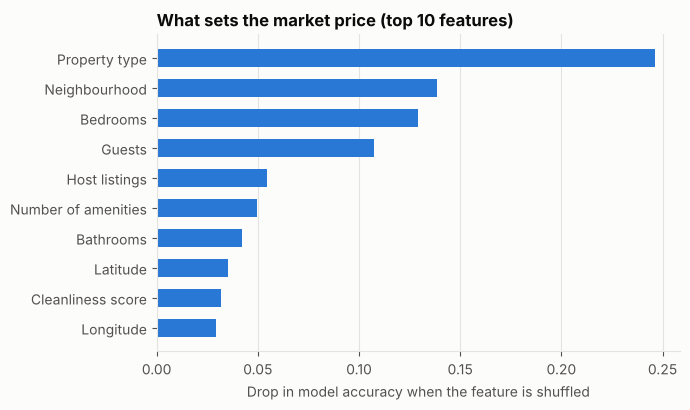

In [3]:
# Which characteristics set the market price? (permutation importance on a model fitted to all listings)
model.fit(X, y)
imp = permutation_importance(model, X, y, n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values().tail(10)

nice = {'accommodates': 'Guests', 'bedrooms': 'Bedrooms', 'bathrooms': 'Bathrooms', 'beds': 'Beds',
        'room_type': 'Room type', 'property_type': 'Property type', 'neighbourhood': 'Neighbourhood',
        'latitude': 'Latitude', 'longitude': 'Longitude', 'minimum_nights': 'Minimum nights',
        'amenities_count': 'Number of amenities', 'calculated_host_listings_count': 'Host listings',
        'review_scores_rating': 'Review score', 'review_scores_location': 'Location score',
        'review_scores_cleanliness': 'Cleanliness score', 'has_pool': 'Pool', 'has_view': 'View',
        'shared_bathroom': 'Shared bathroom', 'superhost': 'Superhost', 'has_hot_tub': 'Hot tub'}
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh([nice.get(i, i) for i in importance.index], importance.values, color=BLUE, height=0.6)
ax.set_title('What sets the market price (top 10 features)')
ax.set_xlabel('Drop in model accuracy when the feature is shuffled')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Findings**
- The benchmark estimates a listing's price with a **median error of about 16%** from its characteristics alone, explaining about **73% of the variation** in (log) price.
- **Property type, neighbourhood and size** (bedrooms, guests) carry most of the weight, followed by how many listings the host runs, the number of amenities and cleanliness. This matches what a host or guest would expect.
- Because the benchmark is typically within ±16%, only gaps **larger than 25%** are treated as meaningful in the next section. Smaller gaps are within the model's normal error.

## 3. Underpriced and overpriced listings

**Price gap** = actual price ÷ market price − 1.
- **Underpriced:** more than 25% below the market price
- **Fair:** within ±25%
- **Overpriced:** more than 25% above the market price

In [4]:
df['price_gap'] = df['price_num'] / df['market_price'] - 1
df['price_position'] = pd.cut(df['price_gap'], [-np.inf, -0.25, 0.25, np.inf],
                              labels=['Underpriced', 'Fair', 'Overpriced'])

pos = df['price_position'].value_counts().reindex(['Underpriced', 'Fair', 'Overpriced']).to_frame('listings')
pos['share'] = pos['listings'] / len(df)
pos['median_price'] = df.groupby('price_position', observed=True)['price_num'].median()
pos['median_market_price'] = df.groupby('price_position', observed=True)['market_price'].median()
pos['median_gap'] = df.groupby('price_position', observed=True)['price_gap'].median()
pos.round(2)

,listings,share,median_price,median_market_price,median_gap
price_position,,,,,
Underpriced,502,0.13,136.0,213.03,-0.34
Fair,2600,0.70,188.0,191.90,-0.03
Overpriced,633,0.17,303.0,196.63,0.44


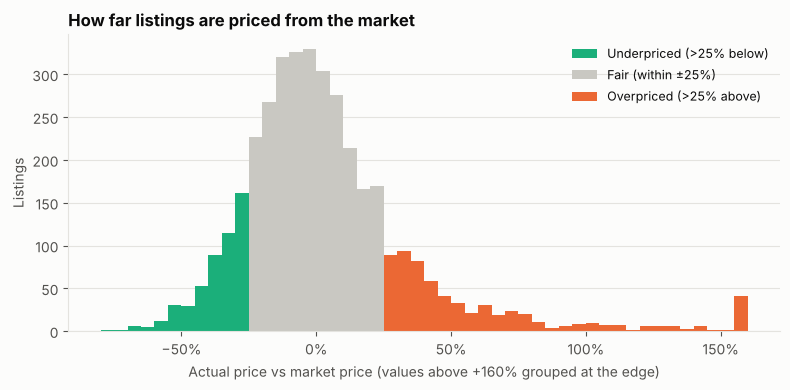

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(-0.8, 1.6, 49)
g = df['price_gap'].clip(upper=1.6)
ax.hist(g[g < -0.25], bins=bins, color=AQUA, label='Underpriced (>25% below)')
ax.hist(g[(g >= -0.25) & (g <= 0.25)], bins=bins, color='#c9c8c2', label='Fair (within ±25%)')
ax.hist(g[g > 0.25], bins=bins, color=ORANGE, label='Overpriced (>25% above)')
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('Actual price vs market price (values above +160% grouped at the edge)')
ax.set_ylabel('Listings')
ax.set_title('How far listings are priced from the market')
ax.legend(frameon=False, fontsize=9)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

## 4. Does demand confirm the gap?

A low price is only an opportunity if guests are already booking the listing. **Demand** is measured by nights booked in the last 12 months (`estimated_occupancy_l365d`):
- **No bookings:** 0 nights (may be new, paused or inactive)
- **Low demand:** below the median of booked listings
- **High demand:** at or above the median of booked listings

In [6]:
occ = df['estimated_occupancy_l365d']
median_booked = occ[occ > 0].median()
df['demand'] = np.select([occ == 0, occ < median_booked], ['No bookings', 'Low demand'], 'High demand')
print(f'Median nights booked (listings with bookings): {median_booked:.0f}')

demand_tab = pd.crosstab(df['price_position'], df['demand'])[['No bookings', 'Low demand', 'High demand']]
demand_tab['median_nights_booked'] = df.groupby('price_position', observed=True)['estimated_occupancy_l365d'].median()
demand_tab

Median nights booked (listings with bookings): 90


demand,No bookings,Low demand,High demand,median_nights_booked
price_position,,,,
Underpriced,119,191,192,54.0
Fair,332,1077,1191,78.0
Overpriced,160,290,183,30.0


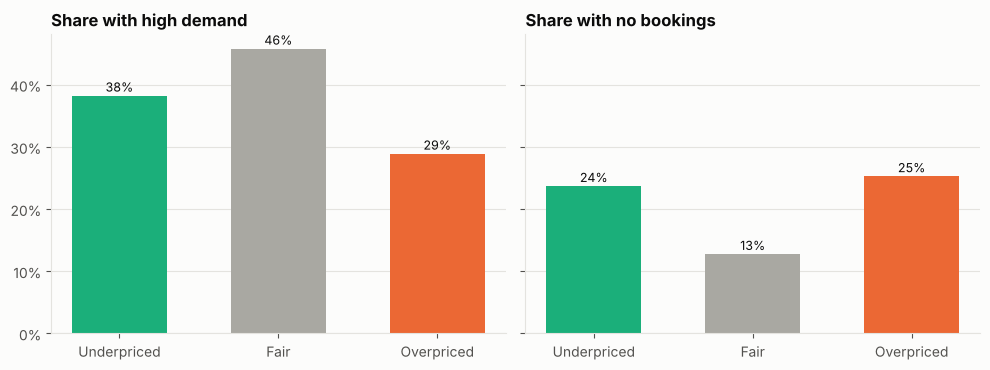

In [7]:
order = ['Underpriced', 'Fair', 'Overpriced']
share_high = df.groupby('price_position', observed=True)['demand'].apply(lambda s: (s == 'High demand').mean()).reindex(order)
share_none = df.groupby('price_position', observed=True)['demand'].apply(lambda s: (s == 'No bookings').mean()).reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, s, title in [(axes[0], share_high, 'Share with high demand'), (axes[1], share_none, 'Share with no bookings')]:
    bars = ax.bar(order, s.values, color=[AQUA, '#a9a8a2', ORANGE], width=0.6)
    for b, v in zip(bars, s.values):
        ax.annotate(f'{v:.0%}', (b.get_x() + b.get_width() / 2, v), xytext=(0, 3),
                    textcoords='offset points', ha='center', fontsize=9)
    ax.set_title(title)
    ax.grid(axis='x', visible=False)
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
plt.tight_layout()
plt.show()

**Findings**
- **Overpriced listings book far less.** Their median is about 30 nights a year, compared with about 78 for fairly priced listings, and about a quarter of them had no bookings at all. Guests appear to notice when a listing is priced above comparable ones.
- **Cheap does not guarantee bookings.** Underpriced listings book *fewer* nights than fairly priced ones (median ~54). For many of them, a low price is likely compensating for something the data does not capture, such as photos, condition or management.
- That is why demand is used to find **real** opportunities: an underpriced listing that is already in high demand can likely charge more without losing guests.

## 5. Pricing opportunities

Combining price position and demand gives four action groups:

| Group | Price | Demand | Suggested action |
|---|---|---|---|
| **Raise price** | Underpriced | High | Already popular and cheaper than comparable listings: test a higher price |
| **Lower price** | Overpriced | Low or none | Priced above the market and not booking: review the price |
| **Premium justified** | Overpriced | High | Guests pay above the market: keep the premium |
| **Fix the listing** | Underpriced | Low or none | Cheap but still not booking: price is not the issue (photos, reviews, quality) |

In [8]:
conditions = [
    (df['price_position'] == 'Underpriced') & (df['demand'] == 'High demand'),
    (df['price_position'] == 'Overpriced') & (df['demand'] != 'High demand'),
    (df['price_position'] == 'Overpriced') & (df['demand'] == 'High demand'),
    (df['price_position'] == 'Underpriced') & (df['demand'] != 'High demand'),
]
groups = ['Raise price', 'Lower price', 'Premium justified', 'Fix the listing']
df['opportunity'] = np.select(conditions, groups, 'No change')

# Revenue opportunity for "Raise price": close HALF the gap to the market price, keep the same nights booked.
# Half the gap is a deliberately cautious assumption, because a higher price may cost some bookings.
raise_ = df['opportunity'] == 'Raise price'
df['suggested_price'] = df['price_num']
df.loc[raise_, 'suggested_price'] = df.loc[raise_, 'price_num'] + 0.5 * (df.loc[raise_, 'market_price'] - df.loc[raise_, 'price_num'])
df['revenue_uplift'] = (df['suggested_price'] - df['price_num']) * df['estimated_occupancy_l365d']

opp = df.groupby('opportunity').agg(listings=('ID', 'size'), median_price=('price_num', 'median'),
                                    median_market_price=('market_price', 'median'),
                                    median_nights_booked=('estimated_occupancy_l365d', 'median'),
                                    revenue_last_12m=('estimated_revenue_l365d', 'sum'),
                                    revenue_uplift=('revenue_uplift', 'sum'))
opp = opp.reindex(groups + ['No change'])
opp.round(0)

,listings,median_price,median_market_price,median_nights_booked,revenue_last_12m,revenue_uplift
opportunity,,,,,,
Raise price,192,140.0,216.0,180.0,5581103.0,1475768.0
Lower price,450,313.0,199.0,12.0,3438986.0,0.0
Premium justified,183,272.0,184.0,174.0,10908877.0,0.0
Fix the listing,310,134.0,211.0,12.0,1152208.0,0.0
No change,2600,188.0,192.0,78.0,50613579.0,0.0


In [9]:
r = df[raise_]
print(f'Raise price group: {len(r)} listings')
print(f'  Median price ${r["price_num"].median():.0f} vs market ${r["market_price"].median():.0f}; '
      f'suggested ${r["suggested_price"].median():.0f}')
print(f'  Combined revenue last 12 months: ${r["estimated_revenue_l365d"].sum():,.0f}')
print(f'  Estimated extra revenue (half the gap, same bookings): ${r["revenue_uplift"].sum():,.0f} '
      f'(+{r["revenue_uplift"].sum() / r["estimated_revenue_l365d"].sum():.0%}), '
      f'median ${r["revenue_uplift"].median():,.0f} per listing')
print(f'  Room types: {r["room_type"].value_counts().to_dict()}')

Raise price group: 192 listings
  Median price $140 vs market $216; suggested $178
  Combined revenue last 12 months: $5,581,103
  Estimated extra revenue (half the gap, same bookings): $1,475,768 (+26%), median $6,446 per listing
  Room types: {'Entire home/apt': 168, 'Private room': 23, 'Shared room': 1}


**Findings**
- **192 listings are underpriced and already in high demand.** They charge a median of **$140 a night against a market price of $216** (about a third less), yet are booked a median of 180 nights a year. Most (168) are entire homes or apartments.
- Closing **only half** of that gap, with the same number of nights booked, would add an estimated **~$1.5M a year** across these listings: about **+26%** on their current revenue, or a median of **~$6,400 per listing**.
- **450 overpriced listings with low or no demand** are an opportunity in the other direction. They are booked a median of only 12 nights a year, so a lower price may win back bookings.

*These estimates are indicative. The benchmark has a typical error of ±16%, and a price increase may reduce bookings somewhat. A host should test the change gradually.*

## 6. Pricing by neighbourhood

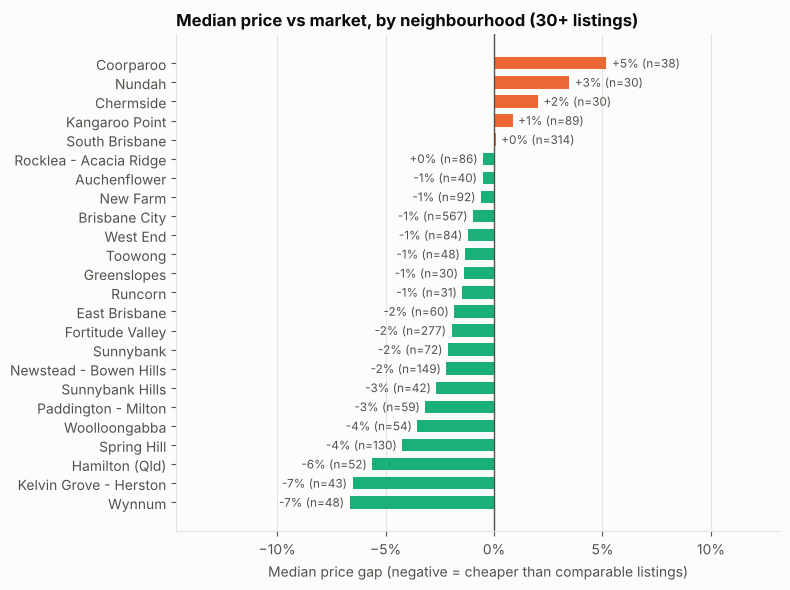

,listings,median_price,median_gap,share_underpriced,raise_price_listings,revenue_uplift
neighbourhood_cleansed,,,,,,
Brisbane City,567,238.0,-0.01,0.12,35,277898.17
New Farm,92,224.5,-0.01,0.12,9,128823.71
South Brisbane,314,207.0,0.00,0.08,12,101829.24
Wynnum,48,186.0,-0.07,0.27,11,80683.83
Fortitude Valley,277,195.0,-0.02,0.08,9,73385.83
Spring Hill,130,180.5,-0.04,0.15,6,69959.53
Newstead - Bowen Hills,149,207.0,-0.02,0.17,9,65770.54
West End,84,191.0,-0.01,0.12,4,36807.21


In [10]:
nb = df.groupby('neighbourhood_cleansed').agg(
    listings=('ID', 'size'), median_price=('price_num', 'median'), median_gap=('price_gap', 'median'),
    share_underpriced=('price_position', lambda s: (s == 'Underpriced').mean()),
    share_overpriced=('price_position', lambda s: (s == 'Overpriced').mean()),
    raise_price_listings=('opportunity', lambda s: (s == 'Raise price').sum()),
    revenue_uplift=('revenue_uplift', 'sum'),
    latitude=('latitude', 'median'), longitude=('longitude', 'median'))
nb_main = nb[nb['listings'] >= 30].sort_values('median_gap')

fig, ax = plt.subplots(figsize=(8, 6))
colors = [AQUA if v < 0 else ORANGE for v in nb_main['median_gap']]
ax.barh(nb_main.index, nb_main['median_gap'], color=colors, height=0.65)
ax.axvline(0, color=MUTED, lw=1)
for i, (v, n) in enumerate(zip(nb_main['median_gap'], nb_main['listings'])):
    ax.annotate(f'{(v if abs(v) >= 0.005 else 0):+.0%} (n={n})', (v, i), xytext=(4 if v >= 0 else -4, 0), textcoords='offset points',
                ha='left' if v >= 0 else 'right', va='center', fontsize=8.5, color=MUTED)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(nb_main['median_gap'].min() - 0.08, nb_main['median_gap'].max() + 0.08)
ax.set_title('Median price vs market, by neighbourhood (30+ listings)')
ax.set_xlabel('Median price gap (negative = cheaper than comparable listings)')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

nb_main.sort_values('revenue_uplift', ascending=False)[
    ['listings', 'median_price', 'median_gap', 'share_underpriced', 'raise_price_listings', 'revenue_uplift']].head(8).round(2)

**Findings**
- Every large neighbourhood is priced close to the market overall (median gaps between about −7% and +5%), so mispricing is mainly a **listing-level** issue rather than a whole-suburb issue.
- The "raise price" opportunity is largest in **Brisbane City**, followed by New Farm and South Brisbane, simply because they have the most listings. **Wynnum** stands out: 27% of its listings are underpriced, the highest share among the larger neighbourhoods.
- These are the areas to look at first in the Power BI dashboard.

## 7. Export for the dashboard

Two files are saved to `exports/`:
- `listings_pricing.csv`: one row per listing, with location, actual vs market price, price gap, demand, action group and estimated uplift.
- `neighbourhood_pricing.csv`: one row per neighbourhood with summary measures.

Host names and free-text fields are left out.

In [11]:
import os
os.makedirs('exports', exist_ok=True)
export = df[['ID', 'name', 'neighbourhood_cleansed', 'latitude', 'longitude', 'room_type', 'property_type',
             'accommodates', 'bedrooms', 'bathrooms', 'review_scores_rating', 'host_is_superhost',
             'price_num', 'market_price', 'price_gap', 'price_position', 'estimated_occupancy_l365d', 'demand',
             'estimated_revenue_l365d', 'opportunity', 'suggested_price', 'revenue_uplift']].rename(columns={
    'ID': 'listing_id', 'name': 'listing_name', 'neighbourhood_cleansed': 'neighbourhood', 'price_num': 'price',
    'estimated_occupancy_l365d': 'nights_booked_12m', 'estimated_revenue_l365d': 'revenue_12m',
    'host_is_superhost': 'superhost'})
export['superhost'] = export['superhost'].map({'t': 'Yes', 'f': 'No'})
for c in ['market_price', 'suggested_price', 'revenue_uplift']:
    export[c] = export[c].round(2)
export['price_gap'] = export['price_gap'].round(4)
export.to_csv('exports/listings_pricing.csv', index=False)

nb_out = nb.reset_index().rename(columns={'neighbourhood_cleansed': 'neighbourhood'})
nb_out.round(4).to_csv('exports/neighbourhood_pricing.csv', index=False)
print(export.shape, nb_out.shape)
export.head()

(3735, 22) (132, 10)


,listing_id,listing_name,neighbourhood,latitude,longitude,room_type,property_type,accommodates,bedrooms,bathrooms,...,price,market_price,price_gap,price_position,nights_booked_12m,demand,revenue_12m,opportunity,suggested_price,revenue_uplift
0,0,The Nestt,Rocklea - Acacia Ridge,-27.557320,153.020270,Entire home/apt,Entire rental unit,2,1.0,1.0,...,97.0,162.11,-0.4017,Underpriced,100,High demand,9700.0,Raise price,129.56,3255.71
1,1,Bayside Bliss - By the Water & Near ...,Wynnum,-27.445790,153.179090,Entire home/apt,Entire guest suite,4,2.0,1.0,...,205.0,169.40,0.2102,Fair,48,Low demand,9840.0,No change,205.00,0.00
2,2,Cozy 1 Bedroom Apartment with Infini...,Fortitude Valley,-27.456050,153.032450,Entire home/apt,Entire rental unit,2,1.0,1.0,...,186.0,179.16,0.0382,Fair,96,High demand,17856.0,No change,186.00,0.00
3,3,City Stay-Executive 1.5 Bedroom,Newstead - Bowen Hills,-27.451701,153.035454,Entire home/apt,Entire rental unit,2,1.0,1.0,...,157.0,140.96,0.1138,Fair,0,No bookings,0.0,No change,157.00,0.00
4,4,Private Oasis! 3Bed/2Bath/1Car ~ 5mi...,Fortitude Valley,-27.458774,153.038180,Entire home/apt,Entire rental unit,6,3.0,2.0,...,300.0,475.67,-0.3693,Underpriced,255,High demand,76500.0,Raise price,387.83,22397.43


## 8. Recommendations and limitations

**Recommendations for hosts and a pricing team**
1. **Raise prices gradually for the 192 underpriced, high-demand listings**, for example in steps of 10%, and watch bookings. Closing half the gap is worth an estimated ~$1.5M a year across these listings.
2. **Review prices for overpriced listings with few or no bookings.** They book far less than fairly priced listings.
3. **Don't cut prices to fix weak listings.** Underpriced listings with low demand are already cheap; better photos, reviews or amenities are more likely to help.
4. **Use property type, location and size as the anchor for pricing**, since these explain most of the market price.

**Limitations**
- The benchmark has a median error of about 16%; it cannot see photos, condition, exact views or seasonal events.
- Prices are a single snapshot. Real Airbnb prices change by date and season.
- The uplift assumes bookings stay the same after a price rise, which is optimistic; closing only half the gap is used to keep the estimate cautious.
- Booked nights are Inside Airbnb estimates, not actual booking records.